# 04 · Representación del conocimiento: lógica proposicional

**Objetivo:** representar conocimiento como fórmulas, decidir **implicación lógica** ($KB \models \alpha$)
por enumeración de modelos, y ver por qué los sistemas reales usan formas restringidas
(cláusulas de Horn) que permiten inferencia en tiempo lineal.

In [1]:
import matplotlib.pyplot as plt

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
import time

from ai_foundations.logic import (
    HornClause,
    conjoin,
    evaluate,
    forward_chaining,
    iff,
    symbols,
    tt_entails,
)

## 1. Modelos y tablas de verdad

$KB \models \alpha$ sii $\alpha$ es verdadera en **todo** modelo donde $KB$ es verdadera.
Modus ponens: $\{P \Rightarrow Q,\ P\} \models Q$.

In [2]:
P, Q = symbols("P Q")
kb = conjoin([P >> Q, P])
print(f"{'P':>6}{'Q':>6}{'KB':>6}{'Q':>6}")
for p in (False, True):
    for q in (False, True):
        m = {P: p, Q: q}
        print(f"{p!s:>6}{q!s:>6}{evaluate(kb, m)!s:>6}{evaluate(Q, m)!s:>6}")
print("KB ⊨ Q:", tt_entails(kb, Q), "| {P ⇒ Q, Q} ⊨ P:", tt_entails(conjoin([P >> Q, Q]), P))

     P     Q    KB     Q
 False False False False
 False  True False  True
  True False False False
  True  True  True  True
KB ⊨ Q: True | {P ⇒ Q, Q} ⊨ P: False


## 2. El mundo del wumpus (fragmento)

Hay brisa en una casilla sii algún vecino tiene un pozo. El agente está en [1,1], no siente brisa;
avanza a [2,1] y siente brisa. ¿Qué puede concluir sin arriesgarse?

In [3]:
B11, B21, P12, P21, P22, P31 = symbols("B11 B21 P12 P21 P22 P31")
kb = conjoin(
    [
        iff(B11, P12 | P21),
        iff(B21, P12 | P22 | P31),
        ~B11,
        B21,
    ]
)
for q in [~P12, ~P21, P22, ~P22, P22 | P31]:
    print(f"KB ⊨ {q!r:<12} {tt_entails(kb, q)}")

KB ⊨ ¬P12         True
KB ⊨ ¬P21         True
KB ⊨ P22          False
KB ⊨ ¬P22         False
KB ⊨ (P22 ∨ P31)  True


El agente **sabe** que [1,2] es segura y que hay un pozo en [2,2] o [3,1], pero no cuál:
la lógica distingue “demostrado falso” de “desconocido”, algo que una lista de reglas ad hoc no hace.

## 3. Encadenamiento hacia adelante (Horn)

Con cláusulas de la forma *premisas ⇒ conclusión* basta propagar hechos: así funcionan los
motores de reglas y Datalog.

In [4]:
rules = [
    HornClause((), "tiene_fiebre"),
    HornClause((), "tiene_tos"),
    HornClause((), "vacunado"),
    HornClause(("tiene_fiebre", "tiene_tos"), "sospecha_respiratoria"),
    HornClause(("sospecha_respiratoria", "vacunado"), "riesgo_bajo"),
    HornClause(("riesgo_bajo",), "tratamiento_ambulatorio"),
]
ok, trace = forward_chaining(rules, "tratamiento_ambulatorio")
print(ok, " → ".join(trace))

True tiene_fiebre → tiene_tos → vacunado → sospecha_respiratoria → riesgo_bajo → tratamiento_ambulatorio


## 4. Costo: enumeración de modelos vs. encadenamiento

Cadena $A_1,\ A_1 \Rightarrow A_2,\ \dots,\ A_{n-1} \Rightarrow A_n$; consulta $A_n$.

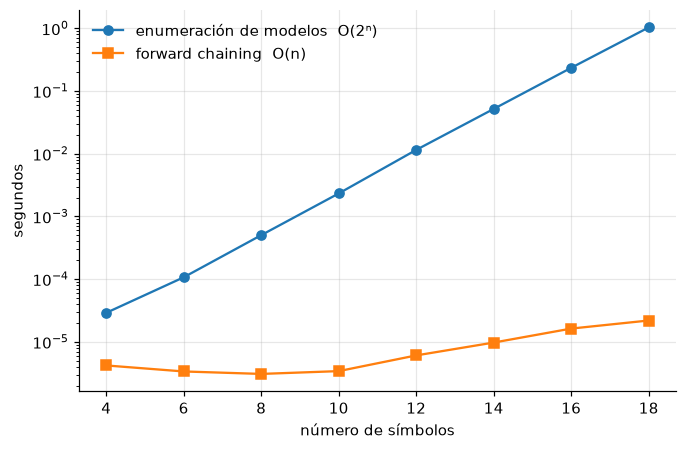

In [5]:
ns = list(range(4, 19, 2))
t_tt, t_fc = [], []
for n in ns:
    A = symbols(" ".join(f"A{i}" for i in range(n)))
    kb = conjoin([A[0], *[A[i] >> A[i + 1] for i in range(n - 1)]])
    horn = [HornClause((), "A0"), *[HornClause((f"A{i}",), f"A{i + 1}") for i in range(n - 1)]]
    t0 = time.perf_counter()
    assert tt_entails(kb, A[-1])
    t_tt.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    assert forward_chaining(horn, f"A{n - 1}")[0]
    t_fc.append(time.perf_counter() - t0)

fig, ax = plt.subplots()
ax.semilogy(ns, t_tt, "o-", label="enumeración de modelos  O(2ⁿ)")
ax.semilogy(ns, t_fc, "s-", label="forward chaining  O(n)")
ax.set_xlabel("número de símbolos")
ax.set_ylabel("segundos")
ax.legend();

## Para llevar

- La lógica separa **conocimiento** (KB) de **inferencia** (algoritmo genérico): el mismo motor
  sirve para cualquier dominio.
- Enumerar modelos es correcto y completo pero exponencial; SAT solvers modernos (DPLL/CDCL)
  y las formas restringidas (Horn) lo hacen práctico.
- La representación simbólica sigue viva: planificadores, verificación formal, bases de
  conocimiento y la capa de herramientas deterministas de los agentes LLM.